# TSP — Heurísticas

**Optimización DS2011 — fase 3.** Vecino más cercano (construye una ruta) y
2-opt (la mejora). No garantizan el óptimo, pero corren rápido incluso en
instancias grandes.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd()
if not (RAIZ / "src" / "tsp").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
from tsp.datos import leer_tsp, matriz_distancias, longitud_ruta
from tsp.heuristicas import vecino_mas_cercano, dos_opt

inst = leer_tsp(RAIZ / "data" / "raw" / "berlin52.tsp")
D = matriz_distancias(inst.coords)
OPTIMO = 7542

## 1. Vecino más cercano

Desde la ciudad actual, salta siempre a la más cercana sin visitar. Rápido,
pero las últimas conexiones suelen quedar largas (miopía).

In [2]:
ruta_nn = vecino_mas_cercano(D, inicio=0)
costo_nn = longitud_ruta(ruta_nn, D)
gap_nn = (costo_nn - OPTIMO) / OPTIMO * 100
print(f"vecino mas cercano: L={costo_nn}  gap={gap_nn:.2f}%")

vecino mas cercano: L=8980  gap=19.07%


**Para cambiar algo en vivo:** `inicio=0` es la ciudad de partida — se puede
probar con cualquier otra (0 a 51) y ver cómo cambia el resultado.

## 2. 2-opt

Mejora local: invierte tramos de la ruta mientras eso la acorte. Estrategia
de primera mejora, evaluando cada movimiento en O(1).

In [3]:
ruta_2opt = dos_opt(ruta_nn, D)
costo_2opt = longitud_ruta(ruta_2opt, D)
gap_2opt = (costo_2opt - OPTIMO) / OPTIMO * 100
print(f"vecino mas cercano + 2-opt: L={costo_2opt}  gap={gap_2opt:.2f}%")
print(f"mejora sobre NN: {costo_nn - costo_2opt} unidades ({costo_nn} -> {costo_2opt})")

vecino mas cercano + 2-opt: L=7967  gap=5.64%
mejora sobre NN: 1013 unidades (8980 -> 7967)


## Ruta final (vecino más cercano + 2-opt) sobre las coordenadas

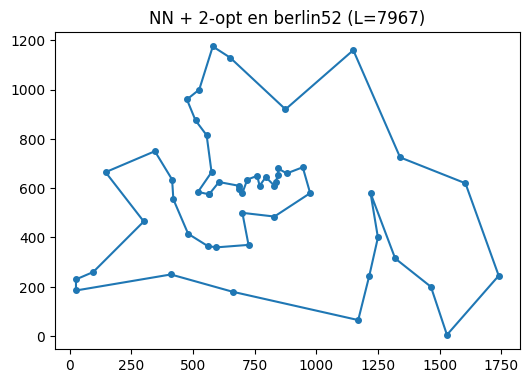

In [4]:
import matplotlib.pyplot as plt

orden = ruta_2opt + [ruta_2opt[0]]
xs, ys = inst.coords[orden, 0], inst.coords[orden, 1]

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(xs, ys, "-o", markersize=4)
ax.set_title(f"NN + 2-opt en berlin52 (L={costo_2opt})")
ax.set_aspect("equal")
plt.show()